# 22. Three-day trajectory benchmark: overall scorecard

This notebook packages Notebook 21 predictions as a trajectory benchmark. It does not train again, change features or select a window. Dynamic Panel is the benchmark model, and its day1/day2/day3 paths are benchmark outputs. Each path is issued from the SAME ZIP and forecast origin. The primary trajectory MAE averages the three absolute errors per path, then averages all 16,380 ZIP-origin paths. All paths have equal length, so it equals the previous pooled MAE mathematically.

Fixed March 1-April 29 training interval, fit April30, May1-28 daily forecast origins, 585 regions. Predictor history updates at each origin, but May never enters parameter fitting. There are 34 candidate columns, with 24 identifiable slopes per horizon plus ZIP fixed effects in this interval. Actual targets are raw daily recorded illness-onset counts, not smoothed three-day means. No per-ZIP score tables are created.

This historical replay uses later-developed cohort/features and retrospective onset records. It is exploratory, not an untouched prospective test. May mainly tests decline. Do not change thresholds/features based on these results and then report the same dates as an independent test.


In [1]:
"""Reusable overall trajectory scoring. No model fitting or feature selection."""
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd

def score_trajectory_archive(prediction_archive, reference_archive, output, model_name='Dynamic Panel FE'):
    prediction_archive,reference_archive,output=Path(prediction_archive),Path(reference_archive),Path(output)
    output.mkdir(parents=True,exist_ok=True)
    with np.load(reference_archive,allow_pickle=False) as ref:
        actual=ref['actual_cases'].copy();ids=ref['zip'].copy();origins=ref['forecast_origins'].copy();horizons=ref['horizons'].copy()
    with np.load(prediction_archive,allow_pickle=False) as candidate:
        assert np.array_equal(candidate['zip'],ids),'Region IDs/order must match reference'
        assert np.array_equal(candidate['forecast_origins'],origins),'Forecast origins/order must match reference'
        assert np.array_equal(candidate['horizons'],horizons),'Horizons must match reference'
        assert np.array_equal(candidate['actual_cases'],actual),'Actual targets must match reference'
        raw=candidate['raw_predictions'].copy()
    assert raw.shape==actual.shape==(585,28,3)
    assert np.array_equal(horizons,[1,2,3]) and np.isfinite(raw).all() and np.isfinite(actual).all()
    predicted=np.maximum(raw,0);errors=predicted-actual
    path_mae=np.abs(errors).mean(axis=2)
    path_rmse=np.sqrt(np.mean(errors**2,axis=2))
    slope_actual=(actual[:,:,2]-actual[:,:,0])/2
    slope_predicted=(predicted[:,:,2]-predicted[:,:,0])/2
    t=np.sign(slope_actual).astype(int);p=np.sign(slope_predicted).astype(int)
    astep=np.sign(np.diff(actual,axis=2)).astype(int);pstep=np.sign(np.diff(predicted,axis=2)).astype(int)
    shape_agreement=(astep==pstep).all(axis=2)
    confusion=np.array([[np.sum((t==a)&(p==b)) for b in [-1,0,1]] for a in [-1,0,1]])
    recalls=np.divide(np.diag(confusion),confusion.sum(axis=1),out=np.full(3,np.nan),where=confusion.sum(axis=1)>0)
    def record(name,value,unit,role,definition):return dict(model=model_name,metric=name,value=float(value),unit=unit,role=role,definition=definition)
    rows=[record('trajectory_MAE',path_mae.mean(),'cases','primary','Mean of three absolute daily errors per ZIP-origin path, then mean across all paths'),
          record('pooled_RMSE',np.sqrt(np.mean(errors**2)),'cases','secondary','Root mean squared error across all ZIP-origin-horizon targets'),
          record('mean_path_RMSE',path_rmse.mean(),'cases','secondary','Mean of each individual three-point path RMSE; differs from pooled RMSE'),
          record('mean_bias',errors.mean(),'cases','diagnostic','Prediction minus actual, pooled across targets'),
          record('slope_MAE',np.abs(slope_predicted-slope_actual).mean(),'cases/day','secondary','Slope=(day3-day1)/2; mean absolute predicted-minus-actual slope error'),
          record('strict_direction_agreement',(p==t).mean(),'proportion','secondary','Sign of day3-day1: negative declining, exact zero flat, positive rising'),
          record('balanced_direction_accuracy',np.nanmean(recalls),'proportion','diagnostic','Mean recall across actual declining, flat and rising classes'),
          record('two_step_shape_agreement',shape_agreement.mean(),'proportion','secondary','Both signs day2-day1 and day3-day2 must match exactly'),
          record('always_flat_direction_reference',(t==0).mean(),'proportion','diagnostic','Direction agreement if every path is classified endpoint-flat'),
          record('all_zero_actual_path_share',(actual==0).all(axis=2).mean(),'proportion','diagnostic','All three actual daily counts are zero')]
    table=pd.DataFrame(rows);table.to_csv(output/'overall_trajectory_scorecard.csv',index=False)
    # Day1=Day3 does not imply the interior point is constant.
    endpoint_flat=t==0;constant=(np.diff(actual,axis=2)==0).all(axis=2)
    groups=[]
    for name,mask in [('all_paths',np.ones_like(t,dtype=bool)),('actual_endpoint_nonflat',~endpoint_flat),('actual_endpoint_flat',endpoint_flat),('actual_all_three_constant',constant),('actual_all_three_zero',(actual==0).all(axis=2)),('actual_endpoint_flat_but_middle_changes',endpoint_flat&~constant)]:
        groups.append(dict(subgroup=name,path_count=int(mask.sum()),trajectory_MAE=float(path_mae[mask].mean()) if mask.any() else None,strict_direction_agreement=float((p[mask]==t[mask]).mean()) if mask.any() else None,two_step_shape_agreement=float(shape_agreement[mask].mean()) if mask.any() else None))
    pd.DataFrame(groups).to_csv(output/'overall_path_subgroups.csv',index=False)
    labels=['Declining','Endpoint-flat','Rising']
    pd.DataFrame(confusion,index=pd.Index(labels,name='Actual'),columns=labels).to_csv(output/'direction_confusion_counts.csv')
    daily=pd.DataFrame({'forecast_origin':pd.to_datetime(origins),'trajectory_MAE':path_mae.mean(axis=0),'slope_MAE':np.abs(slope_predicted-slope_actual).mean(axis=0),'strict_direction_agreement':(p==t).mean(axis=0),'two_step_shape_agreement':shape_agreement.mean(axis=0),'paths_per_origin':len(ids)})
    daily.to_csv(output/'overall_scores_by_forecast_origin.csv',index=False)
    horizon=[]
    for hh,h in enumerate(horizons):
        e=errors[:,:,hh];horizon.append(dict(model=model_name,horizon=int(h),MAE=float(np.abs(e).mean()),RMSE=float(np.sqrt((e*e).mean())),bias=float(e.mean()),observations=e.size))
    pd.DataFrame(horizon).to_csv(output/'horizon_diagnostics.csv',index=False)
    # One common date-block sample preserves contemporaneous spatial dependence.
    rng=np.random.default_rng(20261027);block=7;B=2000;T=len(origins)
    starts=rng.integers(0,T-block+1,size=(B,int(np.ceil(T/block))))
    draw=(starts[:,:,None]+np.arange(block)).reshape(B,-1)[:,:T]
    ci=[]
    for metric in ['trajectory_MAE','slope_MAE','strict_direction_agreement','two_step_shape_agreement']:
        lo,hi=np.quantile(daily[metric].to_numpy()[draw].mean(axis=1),[.025,.975])
        ci.append(dict(metric=metric,ci95_low=float(lo),ci95_high=float(hi),block_days=block,resamples=B,interpretation='Exploratory pointwise interval over 28 forecast origins; conditional on fixed cohort/model. Not model-selection-adjusted.'))
    pd.DataFrame(ci).to_csv(output/'exploratory_date_block_intervals.csv',index=False)
    assert np.isclose(path_mae.mean(),np.abs(errors).mean())
    assert np.isclose(path_mae.mean(),daily.trajectory_MAE.mean())
    assert confusion.sum()==585*28
    contract=dict(primary_metric='trajectory_MAE',primary_direction_threshold=0,targets='Raw daily recorded illness-onset counts, not a three-day moving average',path='Three future daily count predictions issued from the SAME ZIP and forecast origin',prediction_shape=['region','forecast_origin','horizon'],regions=len(ids),forecast_origins=len(origins),paths=int(path_mae.size),target_values=int(actual.size),horizons=horizons.tolist(),forecast_origin_start=str(pd.Timestamp(origins[0]).date()),forecast_origin_end=str(pd.Timestamp(origins[-1]).date()),clipping='max(raw_prediction,0), no rounding',aggregation='Equal weight to all 585x28 ZIP-origin paths, then three horizons equally. Do not sum ZIPs before computing primary score.',slope='(day3-day1)/2, cases/day',direction='Sign of slope; endpoint-flat may include an interior peak or trough',shape='Exact match of BOTH consecutive daily change signs; endpoint slope cannot capture all shapes',forecast_protocol='Fixed March1-April29 2020 parameter-training interval; fit April30, May1-28 origins, no May labels for fitting. Predictors updated through origin.',feature_design='34 candidates, ZIP FE; 24 identifiable slopes per horizon in this interval. Not a predictive selection experiment.',model_role='Dynamic Panel trajectory forecast is the benchmark output for subsequent models.',comparison_rule='Future models must match reference region IDs, forecast origins, horizon order and actual targets. Tune only using declared development data, never May evaluation scores.',limitations='Exploratory replay with later-developed definitions and retrospective onset counts. May covers mostly decline. No untouched-test or outbreak-warning claim.',reference_sha256=hashlib.sha256(reference_archive.read_bytes()).hexdigest(),candidate_sha256=hashlib.sha256(prediction_archive.read_bytes()).hexdigest(),model_name=model_name)
    (output/'benchmark_definition.json').write_text(json.dumps(contract,indent=2),encoding='utf-8')
    (output/'verification.json').write_text(json.dumps(dict(no_model_refitted=True,region_origin_horizon_targets_match_reference=True,primary_path_mean_equals_pooled_MAE=True,primary_score_reconciles_with_daily_scores=True,confusion_count_equals_paths=True,per_zip_score_tables_created=False),indent=2))
    report='# Three-day trajectory benchmark: overall results\n\n'
    report+='Each path contains day1/day2/day3 predictions issued at one ZIP and one forecast origin. The primary score averages each path\'s three absolute errors, then averages 16,380 paths. This is mathematically equal to pooled MAE because all paths contain three equally weighted targets. It is not a new improvement relative to Notebook21. No model is refitted or feature changed.\n\n'
    report+='## Scorecard\n'+table[['metric','value','unit','role']].to_string(index=False)+'\n\n'
    report+='## Findings\nTrajectory MAE is 0.9810 cases, slope MAE is 0.4121 cases/day. Strict endpoint direction agreement is 35.43%, compared with 65.55% for an always-endpoint-flat reference. Both daily movement signs agree on 15.15% of paths. These results do not demonstrate adequate trend capture in the May decline. Endpoint-flat includes paths that rise then fall back to the starting level; it is not a complete shape category.\n\n'
    report+='## Comparison protocol\nDynamic Panel is the benchmark model; its predicted paths are the benchmark trajectories. Each candidate model must output identical region/order/origin/horizon/target arrays. Compare trajectory MAE primarily, with slope/shape and bias as supporting measures. No per-ZIP score tables are produced. May should not be used to tune features, thresholds or models. The saved run is exploratory historical replay, not an untouched final test.\n'
    (output/'RESULTS.md').write_text(report,encoding='utf-8')
    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        dest=output/'figures';dest.mkdir(exist_ok=True)
        fig,axes=plt.subplots(1,2,figsize=(13,4.8),gridspec_kw={'width_ratios':[1.3,1]})
        axes[0].plot(daily.forecast_origin,daily.trajectory_MAE,color='#2563eb',marker='o',markersize=3)
        axes[0].axhline(path_mae.mean(),color='#087f78',ls='--',label=f'Overall MAE {path_mae.mean():.3f}')
        axes[0].set(title='Three-day trajectory error by forecast origin',ylabel='Trajectory MAE (cases)',xlabel='Forecast origin');axes[0].tick_params(axis='x',rotation=30);axes[0].legend(frameon=False);axes[0].grid(alpha=.2)
        normalized=np.divide(confusion,confusion.sum(axis=1)[:,None],out=np.zeros((3,3),float),where=confusion.sum(axis=1)[:,None]>0)
        axes[1].imshow(normalized,vmin=0,vmax=1,cmap='Blues')
        axes[1].set(xticks=range(3),yticks=range(3),xticklabels=labels,yticklabels=labels,xlabel='Predicted direction',ylabel='Actual direction',title='Endpoint direction: row percentages')
        for i in range(3):
            for j in range(3):axes[1].text(j,i,f'{normalized[i,j]:.1%}',ha='center',va='center',color='white' if normalized[i,j]>.5 else '#173654')
        fig.suptitle('Dynamic Panel benchmark: overall three-day trajectory evaluation')
        fig.text(.5,.01,'585 regions, 28 origins, 16,380 paths. Fixed 60-calendar-day training interval. Exploratory May 2020 replay.',ha='center',fontsize=9)
        fig.tight_layout(rect=[0,.05,1,.94]);fig.savefig(dest/'01_trajectory_benchmark_overall.png',dpi=250);plt.close(fig)
    except ImportError:print('Optional figure requires matplotlib.')
    print(table[['metric','value','unit']].to_string(index=False));print(output.resolve())
    return table,output


In [2]:
REPO = Path.cwd()
OUTPUT = REPO / 'trajectory_benchmark_outputs' / 'benchmark_20261027'
display(pd.read_csv(OUTPUT / 'overall_trajectory_scorecard.csv'))
display(pd.read_csv(OUTPUT / 'overall_path_subgroups.csv'))
print((OUTPUT / 'RESULTS.md').read_text(encoding='utf-8'))


,model,metric,value,unit,role,definition
0,Dynamic Panel FE,trajectory_MAE,0.981021,cases,primary,Mean of three absolute daily errors per ZIP-or...
1,Dynamic Panel FE,pooled_RMSE,1.962175,cases,secondary,Root mean squared error across all ZIP-origin-...
2,Dynamic Panel FE,mean_path_RMSE,1.103471,cases,secondary,Mean of each individual three-point path RMSE;...
3,Dynamic Panel FE,mean_bias,0.672855,cases,diagnostic,"Prediction minus actual, pooled across targets"
4,Dynamic Panel FE,slope_MAE,0.412099,cases/day,secondary,Slope=(day3-day1)/2; mean absolute predicted-m...
5,Dynamic Panel FE,strict_direction_agreement,0.354335,proportion,secondary,"Sign of day3-day1: negative declining, exact z..."
6,Dynamic Panel FE,balanced_direction_accuracy,0.426890,proportion,diagnostic,"Mean recall across actual declining, flat and ..."
7,Dynamic Panel FE,two_step_shape_agreement,0.151526,proportion,secondary,Both signs day2-day1 and day3-day2 must match ...
8,Dynamic Panel FE,always_flat_direction_reference,0.655495,proportion,diagnostic,Direction agreement if every path is classifie...
9,Dynamic Panel FE,all_zero_actual_path_share,0.526923,proportion,diagnostic,All three actual daily counts are zero


,subgroup,path_count,trajectory_MAE,strict_direction_agreement,two_step_shape_agreement
0,all_paths,16380,0.981021,0.354335,0.151526
1,actual_endpoint_nonflat,5643,1.712701,0.488038,0.130781
2,actual_endpoint_flat,10737,0.596475,0.284064,0.162429
3,actual_all_three_constant,8850,0.408458,0.320904,0.109831
4,actual_all_three_zero,8631,0.371291,0.328351,0.112617
5,actual_endpoint_flat_but_middle_changes,1887,1.478273,0.111288,0.409115


# Three-day trajectory benchmark: overall results

Each path contains day1/day2/day3 predictions issued at one ZIP and one forecast origin. The primary score averages each path's three absolute errors, then averages 16,380 paths. This is mathematically equal to pooled MAE because all paths contain three equally weighted targets. It is not a new improvement relative to Notebook21. No model is refitted or feature changed.

## Scorecard
                         metric    value       unit       role
                 trajectory_MAE 0.981021      cases    primary
                    pooled_RMSE 1.962175      cases  secondary
                 mean_path_RMSE 1.103471      cases  secondary
                      mean_bias 0.672855      cases diagnostic
                      slope_MAE 0.412099  cases/day  secondary
     strict_direction_agreement 0.354335 proportion  secondary
    balanced_direction_accuracy 0.426890 proportion diagnostic
       two_step_shape_agreement 0.151526 proportion  secon

## Definitions

* Trajectory MAE is the primary quantity. Lower is better.
* Slope = (day3-day1)/2, in cases/day. Slope MAE measures amplitude of trend errors.
* Strict endpoint direction uses the slope sign. Endpoint-flat means day1=day3 and can contain an interior peak/trough. It does not mean all three daily values are identical.
* Two-step shape agreement requires correct signs for BOTH day2-day1 and day3-day2. A positive/zero/negative movement must match exactly. This is a strict descriptive metric, not a tolerance-based clinical outbreak definition.
* Balanced direction accuracy averages recalls across declining/endpoint-flat/rising classes. The always-flat direction reference and all-zero share expose class imbalance.
* Pooled RMSE differs from mean per-path RMSE. Both names and formulas are retained explicitly.
* Date-block intervals are exploratory, conditional on these 28 overlapping forecast origins. No confidence interval is a claim of deployment readiness.


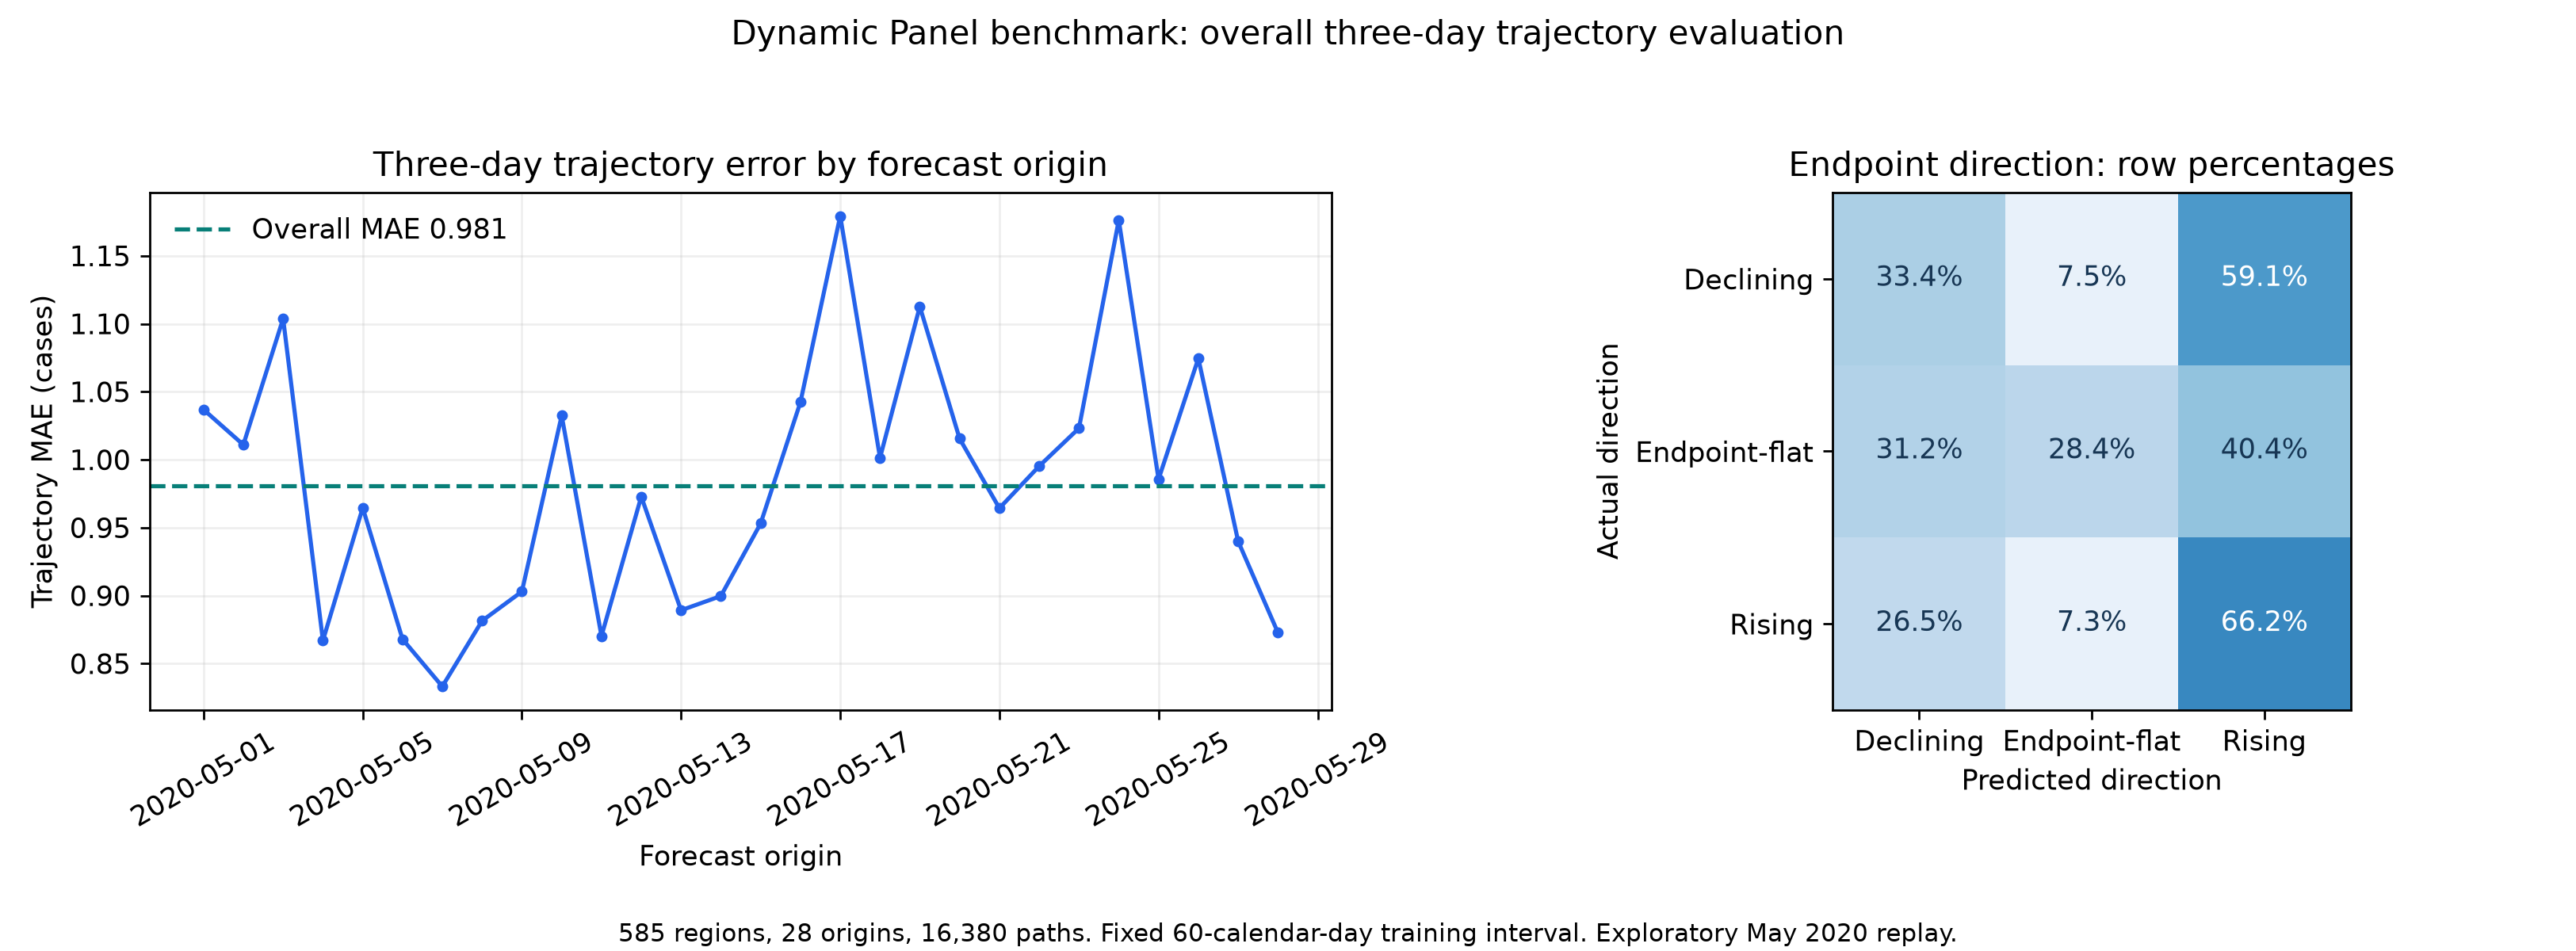

In [3]:
from IPython.display import Image, display
display(Image(filename=str(OUTPUT / 'figures' / '01_trajectory_benchmark_overall.png')))


## Optional rescore of the existing model
This cell only recomputes scores. It does not refit a model. It writes a separate rescore folder.

In [4]:
REFERENCE = REPO / 'fixed60_trajectory_outputs' / 'fixed60_20261027' / 'predictions.npz'
scorecard, RESCORE_FOLDER = score_trajectory_archive(REFERENCE, REFERENCE, REPO / 'trajectory_benchmark_outputs' / 'benchmark_20261027_rescore')
display(scorecard)


                         metric    value       unit
                 trajectory_MAE 0.981021      cases
                    pooled_RMSE 1.962175      cases
                 mean_path_RMSE 1.103471      cases
                      mean_bias 0.672855      cases
                      slope_MAE 0.412099  cases/day
     strict_direction_agreement 0.354335 proportion
    balanced_direction_accuracy 0.426890 proportion
       two_step_shape_agreement 0.151526 proportion
always_flat_direction_reference 0.655495 proportion
     all_zero_actual_path_share 0.526923 proportion
C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\trajectory_benchmark_outputs\benchmark_20261027_rescore


,model,metric,value,unit,role,definition
0,Dynamic Panel FE,trajectory_MAE,0.981021,cases,primary,Mean of three absolute daily errors per ZIP-or...
1,Dynamic Panel FE,pooled_RMSE,1.962175,cases,secondary,Root mean squared error across all ZIP-origin-...
2,Dynamic Panel FE,mean_path_RMSE,1.103471,cases,secondary,Mean of each individual three-point path RMSE;...
3,Dynamic Panel FE,mean_bias,0.672855,cases,diagnostic,"Prediction minus actual, pooled across targets"
4,Dynamic Panel FE,slope_MAE,0.412099,cases/day,secondary,Slope=(day3-day1)/2; mean absolute predicted-m...
5,Dynamic Panel FE,strict_direction_agreement,0.354335,proportion,secondary,"Sign of day3-day1: negative declining, exact z..."
6,Dynamic Panel FE,balanced_direction_accuracy,0.426890,proportion,diagnostic,"Mean recall across actual declining, flat and ..."
7,Dynamic Panel FE,two_step_shape_agreement,0.151526,proportion,secondary,Both signs day2-day1 and day3-day2 must match ...
8,Dynamic Panel FE,always_flat_direction_reference,0.655495,proportion,diagnostic,Direction agreement if every path is classifie...
9,Dynamic Panel FE,all_zero_actual_path_share,0.526923,proportion,diagnostic,All three actual daily counts are zero


## Contract for XGBoost, Random Forest and SEIR comparisons

Supply an NPZ containing `raw_predictions`, `actual_cases`, `zip`, `forecast_origins`, and `horizons`. Predictions and actuals must have shape (585,28,3). ZIP/order/origins/horizon order/targets must match the reference exactly; the scoring function rejects differences. IDs must be Unicode arrays, without pickle objects. Forecast counts must refer to the same raw daily onset target; an SEIR infectious-stock output is not comparable until an explicit observation/incidence mapping is defined. This checker verifies alignment, not whether another model was trained without leakage; retain its training/tuning logs separately.

Use trajectory MAE as the declared primary comparison, supporting slope, shape, bias and class diagnostics. Candidate models must obey the fixed training-interval information boundary. A different tuning strategy must be documented on development data, not optimized on this May scoring period.
